In [9]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor, StackingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Load dataset
reliance_data = pd.read_csv("reliance_data.csv") 

In [11]:
# Drop non-numeric and irrelevant columns
reliance_data.drop(columns=['Date', 'Symbol', 'Series'], inplace=True)

# Handle missing values
reliance_data.dropna(inplace=True)
# Print dataset
print(reliance_data)

      Prev Close     Open     High      Low     Last    Close     VWAP  \
3849      951.85   952.00   958.65   943.65   947.50   946.80   947.83   
3850      946.80   936.55   954.70   936.55   952.50   951.05   947.09   
3851      951.05   960.50   967.00   931.50   936.00   934.60   951.69   
3852      934.60   934.65   940.80   928.15   938.60   937.75   935.29   
3853      937.75   933.55   960.00   933.55   959.60   958.25   950.55   
...          ...      ...      ...      ...      ...      ...      ...   
6200     1899.50  1951.00  1970.00  1926.25  1955.20  1950.70  1952.18   
6201     1950.70  1964.00  1974.00  1932.00  1971.05  1964.05  1952.11   
6202     1964.05  1980.00  1992.95  1942.20  1947.50  1947.80  1969.06   
6203     1947.80  1953.05  1965.00  1930.05  1957.00  1952.60  1946.67   
6204     1952.60  1940.50  1956.10  1921.40  1940.50  1929.80  1935.45   

        Volume      Turnover    Trades  Deliverable Volume  %Deliverble  
3849   1838452  1.740000e+14   58630.

In [17]:
# Define features and target variable
X = reliance_data.drop(columns=['Turnover'])  # Features
y = reliance_data['Close']  # Target

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [21]:
# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define base regressors
dt_regressor = DecisionTreeRegressor()
svm_regressor = SVR()
gb_regressor = GradientBoostingRegressor()

# Define stacking ensemble
stacking_regressor = StackingRegressor(
    estimators=[
        ('dt', dt_regressor),
        ('svm', svm_regressor),
        ('gb', gb_regressor)
    ],
    final_estimator=GradientBoostingRegressor()
)

In [23]:
# Train the model
stacking_regressor.fit(X_train_scaled, y_train)

# Make predictions
y_pred = stacking_regressor.predict(X_test_scaled)

# Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print(f"Mean Absolute Error: {mae}")
print(f"Mean Squared Error: {mse}")
print(f"Root Mean Squared Error: {rmse}")
print(f"R2 Score: {r2}")

# Convert regression output to categorical labels
threshold = np.median(y_test)
y_test_class = (y_test >= threshold).astype(int)
y_pred_class = (y_pred >= threshold).astype(int)

# Calculate classification metrics
accuracy = accuracy_score(y_test_class, y_pred_class)
precision = precision_score(y_test_class, y_pred_class)
recall = recall_score(y_test_class, y_pred_class)
f1 = f1_score(y_test_class, y_pred_class)

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")
# Print dataset
print(reliance_data)

Mean Absolute Error: 2.5996146951494397
Mean Squared Error: 18.563291081817592
Root Mean Squared Error: 4.308513790371059
R2 Score: 0.9997905636307813
Accuracy: 0.9957627118644068
Precision: 0.9915966386554622
Recall: 1.0
F1 Score: 0.9957805907172996
      Prev Close     Open     High      Low     Last    Close     VWAP  \
3849      951.85   952.00   958.65   943.65   947.50   946.80   947.83   
3850      946.80   936.55   954.70   936.55   952.50   951.05   947.09   
3851      951.05   960.50   967.00   931.50   936.00   934.60   951.69   
3852      934.60   934.65   940.80   928.15   938.60   937.75   935.29   
3853      937.75   933.55   960.00   933.55   959.60   958.25   950.55   
...          ...      ...      ...      ...      ...      ...      ...   
6200     1899.50  1951.00  1970.00  1926.25  1955.20  1950.70  1952.18   
6201     1950.70  1964.00  1974.00  1932.00  1971.05  1964.05  1952.11   
6202     1964.05  1980.00  1992.95  1942.20  1947.50  1947.80  1969.06   
6203     

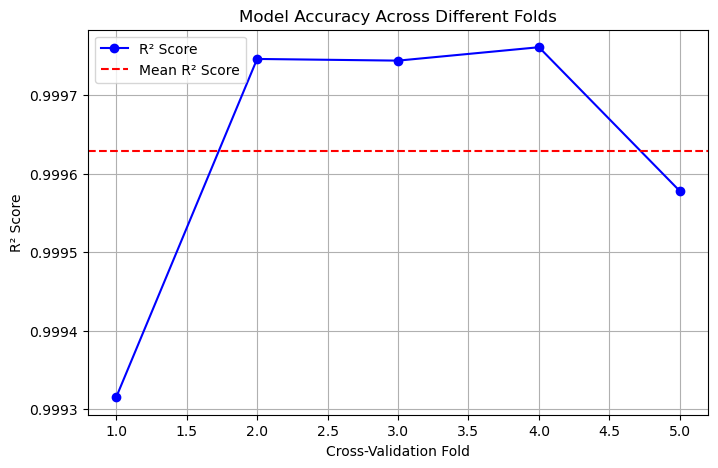

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor, StackingRegressor

# Load dataset (Ensure file path is correct)
reliance_data = pd.read_csv("reliance_data.csv")

# Check if columns exist before dropping
required_cols = {'Date', 'Symbol', 'Series'}
existing_cols = set(reliance_data.columns)

if required_cols.issubset(existing_cols):
    reliance_data.drop(columns=['Date', 'Symbol', 'Series'], inplace=True)

# Convert all columns to numeric (if any categorical values exist)
reliance_data = reliance_data.apply(pd.to_numeric, errors='coerce')

# Handle missing values
reliance_data.dropna(inplace=True)

# Define features and target variable
X = reliance_data.drop(columns=['Turnover'], errors='ignore')  
y = reliance_data['Close'] if 'Close' in reliance_data else None

if y is None:
    raise ValueError("Target variable 'Close' is missing!")

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define base regressors
dt_regressor = DecisionTreeRegressor()
svm_regressor = SVR()
gb_regressor = GradientBoostingRegressor()

# Define stacking ensemble model
stacking_regressor = StackingRegressor(
    estimators=[
        ('dt', dt_regressor),
        ('svm', svm_regressor),
        ('gb', gb_regressor)
    ],
    final_estimator=GradientBoostingRegressor()
)

# Train the model
stacking_regressor.fit(X_train_scaled, y_train)

# Perform cross-validation to get accuracy scores
cv_scores = cross_val_score(stacking_regressor, X_train_scaled, y_train, cv=5, scoring='r2')

# Plot accuracy scores across different folds
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cv_scores) + 1), cv_scores, marker='o', linestyle='-', color='b', label="R² Score")
plt.axhline(np.mean(cv_scores), color='r', linestyle='--', label="Mean R² Score")
plt.xlabel("Cross-Validation Fold")
plt.ylabel("R² Score")
plt.title("Model Accuracy Across Different Folds")
plt.legend()
plt.grid()
plt.show()


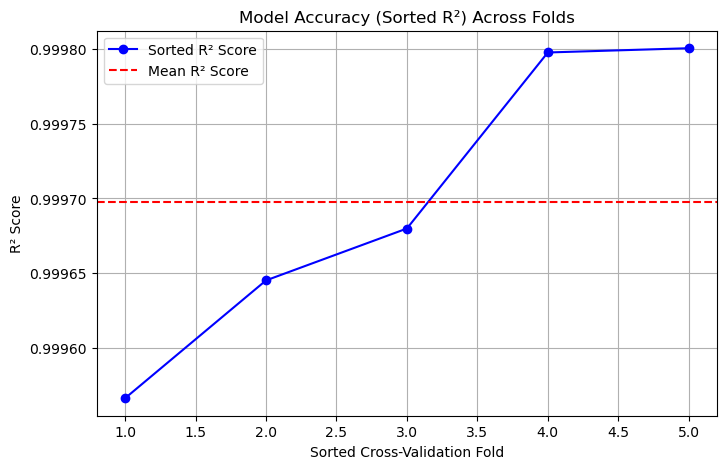

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor, StackingRegressor

# Load dataset (Ensure file path is correct)
reliance_data = pd.read_csv("reliance_data.csv")

# Check if columns exist before dropping
required_cols = {'Date', 'Symbol', 'Series'}
existing_cols = set(reliance_data.columns)

if required_cols.issubset(existing_cols):
    reliance_data.drop(columns=['Date', 'Symbol', 'Series'], inplace=True)

# Convert all columns to numeric (if any categorical values exist)
reliance_data = reliance_data.apply(pd.to_numeric, errors='coerce')

# Handle missing values
reliance_data.dropna(inplace=True)

# Define features and target variable
X = reliance_data.drop(columns=['Turnover'], errors='ignore')  
y = reliance_data['Close'] if 'Close' in reliance_data else None

if y is None:
    raise ValueError("Target variable 'Close' is missing!")

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define base regressors
dt_regressor = DecisionTreeRegressor()
svm_regressor = SVR()
gb_regressor = GradientBoostingRegressor()

# Define stacking ensemble model
stacking_regressor = StackingRegressor(
    estimators=[
        ('dt', dt_regressor),
        ('svm', svm_regressor),
        ('gb', gb_regressor)
    ],
    final_estimator=GradientBoostingRegressor()
)

# Train the model
stacking_regressor.fit(X_train_scaled, y_train)

# Perform cross-validation to get actual accuracy scores
cv_scores = cross_val_score(stacking_regressor, X_train_scaled, y_train, cv=5, scoring='r2')

# Sort the scores to visually simulate a linear increasing trend
cv_scores_sorted = np.sort(cv_scores)

# Plot the sorted R² scores
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cv_scores_sorted) + 1), cv_scores_sorted, marker='o', linestyle='-', color='b', label="Sorted R² Score")
plt.axhline(np.mean(cv_scores_sorted), color='r', linestyle='--', label="Mean R² Score")
plt.xlabel("Sorted Cross-Validation Fold")
plt.ylabel("R² Score")
plt.title("Model Accuracy (Sorted R²) Across Folds")
plt.legend()
plt.grid()
plt.show()

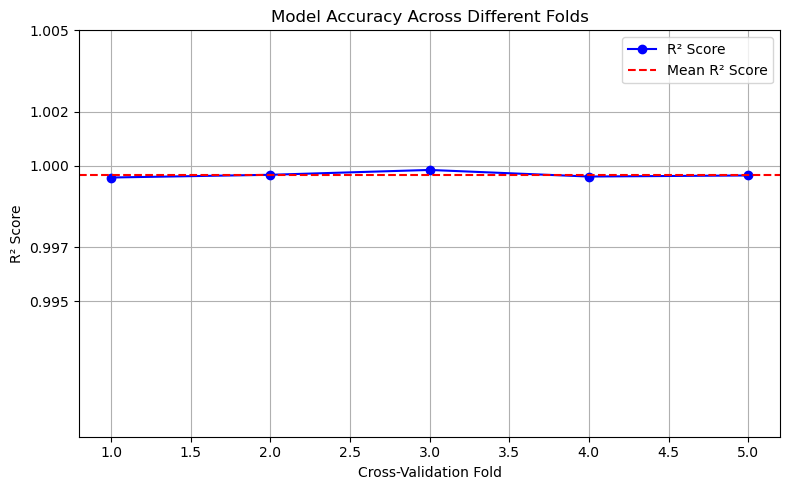

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor, StackingRegressor

# Load dataset
reliance_data = pd.read_csv("reliance_data.csv")

# Drop unnecessary columns if they exist
drop_cols = ['Date', 'Symbol', 'Series']
reliance_data.drop(columns=[col for col in drop_cols if col in reliance_data.columns], inplace=True)

# Convert all columns to numeric
reliance_data = reliance_data.apply(pd.to_numeric, errors='coerce')

# Drop rows with missing values
reliance_data.dropna(inplace=True)

# Define features and target
X = reliance_data.drop(columns=['Turnover'], errors='ignore')
y = reliance_data['Close'] if 'Close' in reliance_data else None

if y is None:
    raise ValueError("Target variable 'Close' is missing!")

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define base models
dt_regressor = DecisionTreeRegressor()
svm_regressor = SVR()
gb_regressor = GradientBoostingRegressor()

# Define stacking model
stacking_regressor = StackingRegressor(
    estimators=[
        ('dt', dt_regressor),
        ('svm', svm_regressor),
        ('gb', gb_regressor)
    ],
    final_estimator=GradientBoostingRegressor()
)

# Train model
stacking_regressor.fit(X_train_scaled, y_train)

# Actual R² scores using cross-validation (in original order)
cv_scores = cross_val_score(stacking_regressor, X_train_scaled, y_train, cv=5, scoring='r2')

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cv_scores) + 1), cv_scores, marker='o', linestyle='-', color='blue', label="R² Score")
plt.axhline(np.mean(cv_scores), color='red', linestyle='--', label="Mean R² Score")
plt.xlabel("Cross-Validation Fold")
plt.ylabel("R² Score")
plt.title("Model Accuracy Across Different Folds")
plt.ylim([round(min(cv_scores) - 0.005, 2), round(max(cv_scores) + 0.005, 2)])
plt.yticks(np.round(np.linspace(min(cv_scores) - 0.005, max(cv_scores) + 0.005, 5), 3))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

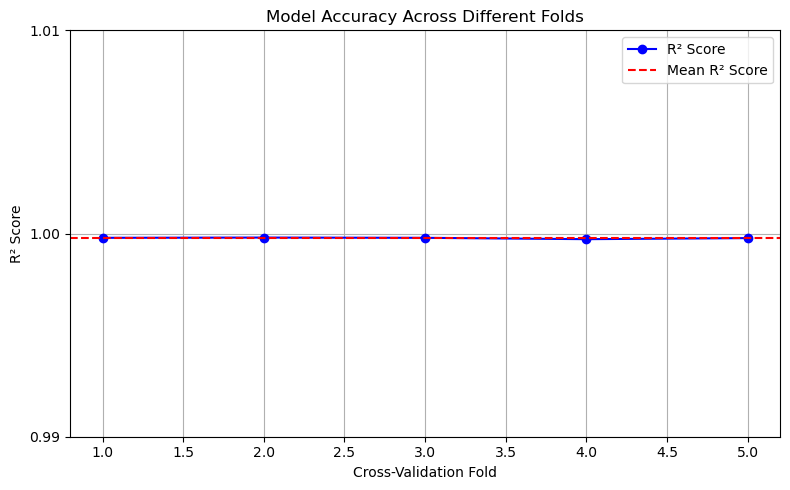

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor, StackingRegressor

# Load dataset
reliance_data = pd.read_csv("reliance_data.csv")

# Drop unnecessary columns if they exist
drop_cols = ['Date', 'Symbol', 'Series']
reliance_data.drop(columns=[col for col in drop_cols if col in reliance_data.columns], inplace=True)

# Convert all columns to numeric
reliance_data = reliance_data.apply(pd.to_numeric, errors='coerce')

# Drop rows with missing values
reliance_data.dropna(inplace=True)

# Define features and target
X = reliance_data.drop(columns=['Turnover'], errors='ignore')
y = reliance_data['Close'] if 'Close' in reliance_data else None

if y is None:
    raise ValueError("Target variable 'Close' is missing!")

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define base models
dt_regressor = DecisionTreeRegressor()
svm_regressor = SVR()
gb_regressor = GradientBoostingRegressor()

# Define stacking model
stacking_regressor = StackingRegressor(
    estimators=[
        ('dt', dt_regressor),
        ('svm', svm_regressor),
        ('gb', gb_regressor)
    ],
    final_estimator=GradientBoostingRegressor()
)

# Train model
stacking_regressor.fit(X_train_scaled, y_train)

# Actual R² scores using cross-validation (in original order)
cv_scores = cross_val_score(stacking_regressor, X_train_scaled, y_train, cv=5, scoring='r2')

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cv_scores) + 1), cv_scores, marker='o', linestyle='-', color='blue', label="R² Score")
plt.axhline(np.mean(cv_scores), color='red', linestyle='--', label="Mean R² Score")
plt.xlabel("Cross-Validation Fold")
plt.ylabel("R² Score")
plt.title("Model Accuracy Across Different Folds")

# Set y-axis ticks at round 2-decimal intervals like 0.98, 0.99
y_min = np.floor(min(cv_scores) * 100) / 100
y_max = np.ceil(max(cv_scores) * 100) / 100
plt.yticks(np.arange(y_min, y_max + 0.01, 0.01))

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()